In [ ]:
import ee
import geemap
import warnings
import os
warnings.filterwarnings('ignore')
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import Point, Polygon
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

import ee
import geemap

# 1. Authenticate your account (only needed once or if your token expires)
try:
    ee.Initialize()
except Exception as e:
    ee.Authenticate()
    ee.Initialize()

print("🚀 Success! Google Earth Engine initialized safely.")

# 2. Spawn the map layout and explicitly skip geemap's background init check
m = geemap.Map(ee_initialize=False)

In [5]:
# 1. Map your local geojson vector file path
study_area = 'Ga_study_area.geojson'

# 2. Pass it directly as the required argument
roi = geemap.geojson_to_ee(geo_json=study_area)

print("✅ Success! GeoJSON vector geometry successfully converted to an Earth Engine object.")

✅ Success! GeoJSON vector geometry successfully converted to an Earth Engine object.


In [6]:
# 1. Define explicit date objects for our loop processing framework
start_date_obj = datetime.date(2026, 1, 1)
end_date_obj = datetime.date(2026, 6, 30)
total_days = (end_date_obj - start_date_obj).days

# 2. Build a server-side list of dates to loop through
date_list = [ee.Date(start_date_obj.strftime('%Y-%m-%d')).advance(i, 'day') for i in range(total_days)]
ee_date_list = ee.List(date_list)

In [7]:
def combine_daily_granules_robust(date):
    """Server-side function to merge granules while preserving the study area footprint"""
    date = ee.Date(date)
    
    day_collection = (ee.ImageCollection("MODIS/061/MCD19A2_GRANULES")
                      .filterBounds(roi)
                      .filterDate(date, date.advance(1, 'day'))
                      .select('Optical_Depth_055'))
    
    # Create the daily mosaic map
    daily_mosaic = day_collection.mosaic()
    
    # CRITICAL FIX: Clip the image to your AOI boundary box. 
    # This forces Earth Engine to retain the spatial geometry coordinates, 
    # even on days when the satellite didn't capture a valid pixel.
    daily_mosaic_clipped = daily_mosaic.clip(roi)
    
    date_string = date.format('YYYYMMDD')
    band_name = ee.String('AOD_').cat(date_string)
    
    return daily_mosaic_clipped.rename([band_name])

clean_daily_collection = ee.ImageCollection(ee.List(date_list).map(combine_daily_granules_robust))

In [8]:
# Collapse the 365 daily layers into a single image containing 365 bands
time_series_image = clean_daily_collection.toBands()

# 2. Generate a structured 1km spatial sampling grid template
sampling_grid = ee.FeatureCollection.randomPoints(roi, points=500, seed=42)

print("⏳ STEP 4.4: Fetching multi-band satellite data layer from server...")
raw_server_output = time_series_image.reduceRegions(
    collection=sampling_grid,
    reducer=ee.Reducer.first(),
    scale=1000
).getInfo()

⏳ STEP 4.4: Fetching multi-band satellite data layer from server...


In [9]:
start_date = datetime.date(2026, 1, 1)
total_days = 182
date_range = [(start_date + datetime.timedelta(days=i)).strftime('%Y-%m-%d') for i in range(total_days)]

spatial_nodes = []
features_list = raw_server_output.get('features', [])

for feature in features_list:
    geom = feature.get('geometry', {})
    if 'coordinates' in geom:
        spatial_nodes.append({
            'node_lon': geom['coordinates'][0],
            'node_lat': geom['coordinates'][1]
        })

template_records = []
for node in spatial_nodes:
    for current_date in date_range:
        template_records.append({
            'date_str': current_date,
            'latitude': node['node_lat'],
            'longitude': node['node_lon'],
            'AOD_Raw': np.nan  # Initialize all AOD values as missing (NaN)
        })

df_aligned_panel = pd.DataFrame(template_records)
df_aligned_panel['lookup_key'] = (df_aligned_panel['date_str'] + "_" + 
                                  df_aligned_panel['latitude'].round(4).astype(str) + "_" + 
                                  df_aligned_panel['longitude'].round(4).astype(str))

In [10]:
gee_extracted_values = {}

for feature in features_list:
    properties = feature.get('properties', {})
    geom = feature.get('geometry', {})
    if 'coordinates' not in geom:
        continue
        
    lat = geom['coordinates'][1]
    lon = geom['coordinates'][0]
    
    for key, value in properties.items():
        if 'AOD_' in key:
            date_part = key.split('AOD_')[1].split('_')[0]
            try:
                formatted_date = pd.to_datetime(date_part, format='%Y%m%d').strftime('%Y-%m-%d')
                lookup_key = f"{formatted_date}_{round(lat, 4)}_{round(lon, 4)}"
                gee_extracted_values[lookup_key] = value
            except Exception:
                continue

df_aligned_panel['AOD_Raw'] = df_aligned_panel['lookup_key'].map(gee_extracted_values)
df_aligned_panel = df_aligned_panel.drop(columns=['lookup_key'])

In [11]:
# Apply the NASA product scale factor (0.001)
df_aligned_panel['AOD_Raw'] = pd.to_numeric(df_aligned_panel['AOD_Raw'], errors='coerce') * 0.001
df_aligned_panel.loc[df_aligned_panel['AOD_Raw'] <= 0, 'AOD_Raw'] = np.nan

df_aligned_panel['month'] = pd.to_datetime(df_aligned_panel['date_str']).dt.month

gdf_annual_raw_aod = gpd.GeoDataFrame(
    df_aligned_panel,
    geometry=gpd.points_from_xy(df_aligned_panel.longitude, df_aligned_panel.latitude),
    crs="EPSG:4326"
)

gdf_annual_raw_aod = gdf_annual_raw_aod.sort_values(['date_str', 'latitude', 'longitude']).reset_index(drop=True)

In [14]:
# Export to clean GeoJSON and CSV
gdf_annual_raw_aod.to_file('Accra_aod_Clean.geojson', driver='GeoJSON')
gdf_annual_raw_aod.drop(columns=['geometry']).to_csv('Accra_aod_Clean.csv', index=False)

<Axes: >

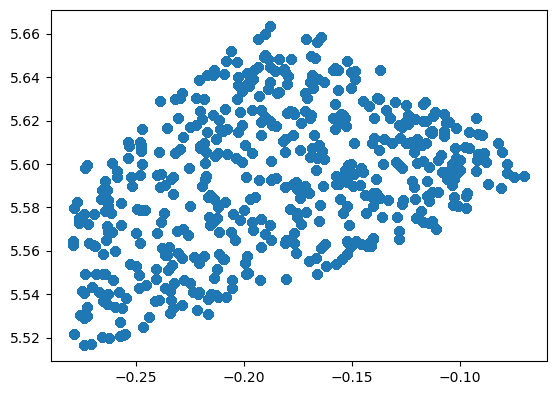

In [13]:
gdf_annual_raw_aod.plot()